# Phase 06 — Q-learning for SYNTHETIC diabetes education interactions
No clinical diagnosis, prescribing, medication adjustment or health-outcome optimization. State includes prediction output band, simulated knowledge/engagement, evidence availability, safety restriction, previous action and remaining budget. Finite action space contains only six educational choices. See docs/rl_mdp.md for transition/reward assumptions.

Q(s,a) ← Q(s,a) + α [r + γ max Q(s′,a′) − Q(s,a)]. For terminal **or horizon truncation**, TD target is r because remaining budget is part of this finite episodic MDP. Selection and evaluation use the shared serving decision selector (mask + unseen-state fallback). Validation and test simulator seeds are disjoint from episode seeds. Baseline authored before experiments, not tuned against Q results.

## Reward design and transition assumptions

Reward version education-reward-1.0: restricted disallowed educational action -20; otherwise -0.2 step cost +1.5 per simulated knowledge increment +0.5 per engagement increment; unsupported action -4; immediate repetition -0.75; evidence-supported general/show +0.3; educational completion +6, appropriate restricted handoff +2; normal handoff -1. These are engineered learning proxies, not measured outcomes.

Explain limitations raises knowledge with probability .8 when prediction present. General/show raises knowledge with probability .65/.8 and engagement .45 when evidence exists. Comprehension raises engagement .75 and completes only if pre-action knowledge=high, engagement>=medium, evidence available. Clarification simulates new evidence (.7) and engagement (.5); this is not fabricated evidence in the deployed app. Levels saturate at high; band and safety are fixed. Completion/referral terminates; six-step budget truncates. Previous-action and remaining-budget fields ensure history/horizon are explicit in observation.

## Baseline and seed splits

Fixed baseline: restricted→clinician; no evidence→clarification; high knowledge+engagement→comprehension; low engagement→comprehension; low knowledge with available prediction→limitations unless repeated; sufficient evidence→show unless repeated, else general education. Authored before results, no tuning to force Q-learning superiority.

Training: three seeds 11/29/47, 8000 episodes each (episode RNG seed=training_seed*1,000,000+episode). Validation 200000–200099 selects one policy. Held-out 100000–100299 used only for evaluation, same scenarios for Q and baseline. Serving-policy evaluation includes the same visit-count fallback and mask as runtime. Unmasked pure-Q is diagnostic only. Runtime mask blocks actions unsupported by safety/evidence context; it is not a claim that learned Q alone guarantees safety.

## Export

artifacts/policies/education-q-1.1/q_table.npz (numeric Q/visits, no pickle), manifest.json (encoder categories/actions/reward/config/seeds/metrics/environment/SHA256). experiments/results/phase06 stores real history/evaluation; experiments/figures/phase06 stores three real figures. No request retraining. Default runtime knowledge/engagement are simulated medium assumptions, not measured personal attributes. Only one next interaction is selected per actual API run.


In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'pyproject.toml').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
%matplotlib inline
from backend.app.rl.mdp import *
from backend.app.rl.reward import reward
from backend.app.rl.experiments import run_experiments
import numpy as np
print(STATE_FIELDS,SHAPE,ACTIONS,REWARD_VERSION)

('prediction_band', 'knowledge', 'engagement', 'evidence', 'safety', 'previous_action', 'remaining') (3, 3, 3, 3, 2, 7, 7) ('EXPLAIN_PREDICTION_LIMITATIONS', 'PROVIDE_GENERAL_EDUCATION', 'SHOW_EVIDENCE', 'ASK_COMPREHENSION_QUESTION', 'REQUEST_CLARIFICATION', 'SUGGEST_CLINICIAN_DISCUSSION') education-reward-1.0


## Environment validation and state/action encoding
Seeded transition noise models only fictitious learning/engagement; it is not patient data. Previous action makes repetition penalty Markov; remaining budget makes truncation explicit.

In [2]:
a=EducationEnv();b=EducationEnv()
assert a.reset(seed=123)==b.reset(seed=123)
for action in [4,1,3]:
    x=a.step(action);y=b.step(action);assert x==y
    print(x)
    if x[2] or x[3]:break
assert encode((0,0,0,0,0,6,6))>=0

((0, 2, 2, 1, 1, 4, 5), 0.3, False, False, {'simulated': True, 'completed': False, 'unsafe_attempt': 0, 'unsupported': 0, 'reward_version': 'education-reward-1.0'})
((0, 2, 2, 1, 1, 1, 4), -20.0, False, False, {'simulated': True, 'completed': False, 'unsafe_attempt': 1, 'unsupported': 0, 'reward_version': 'education-reward-1.0'})
((0, 2, 2, 1, 1, 3, 3), -20.0, False, False, {'simulated': True, 'completed': False, 'unsafe_attempt': 1, 'unsupported': 0, 'reward_version': 'education-reward-1.0'})


## Q initialization, epsilon-greedy, Bellman update and real training loop
The following functions are executed by the experiment harness, not merely displayed.

In [3]:
import numpy as np
from backend.app.rl.mdp import EducationEnv,N_STATES,encode

def td_update(q,s,a,r,next_s,terminated,truncated,alpha,gamma):
    target=r if terminated or truncated else r+gamma*float(q[next_s].max())
    q[s,a]+=alpha*(target-q[s,a])
    return float(target)

def train(seed,episodes=8000,alpha=.15,gamma=.95):
    rng=np.random.default_rng(seed)
    q=np.zeros((N_STATES,6),dtype=np.float64);visits=np.zeros(N_STATES,dtype=np.int64)
    env=EducationEnv(); history=[]
    for episode in range(episodes):
        state,_=env.reset(seed=seed*1_000_000+episode)
        epsilon=max(.05,1.0*(.9994**episode));total=0.;length=0;unsafe=0
        while True:
            row=encode(state);visits[row]+=1
            # Training explores all six educational actions, including unsupported contexts.
            action=int(rng.integers(6)) if rng.random()<epsilon else int(np.argmax(q[row]))
            new,r,term,trunc,info=env.step(action)
            td_update(q,row,action,r,encode(new),term,trunc,alpha,gamma)
            total+=r;length+=1;unsafe+=info['unsafe_attempt'];state=new
            if term or trunc:break
        history.append({'seed':seed,'episode':episode,'reward':total,'length':length,'completed':int(info['completed']),'unsafe_attempts':unsafe,'epsilon':epsilon})
    return q,visits,history


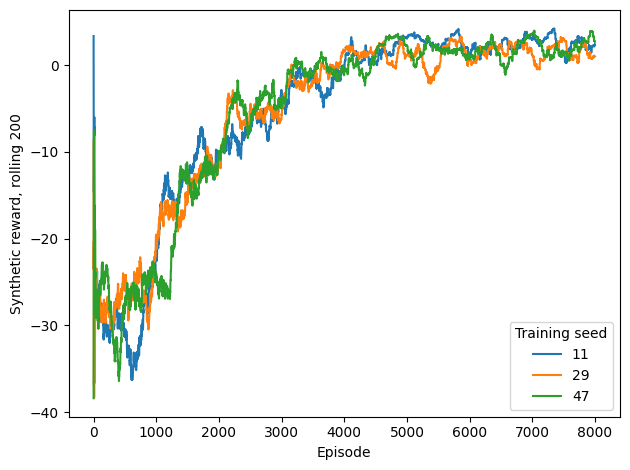

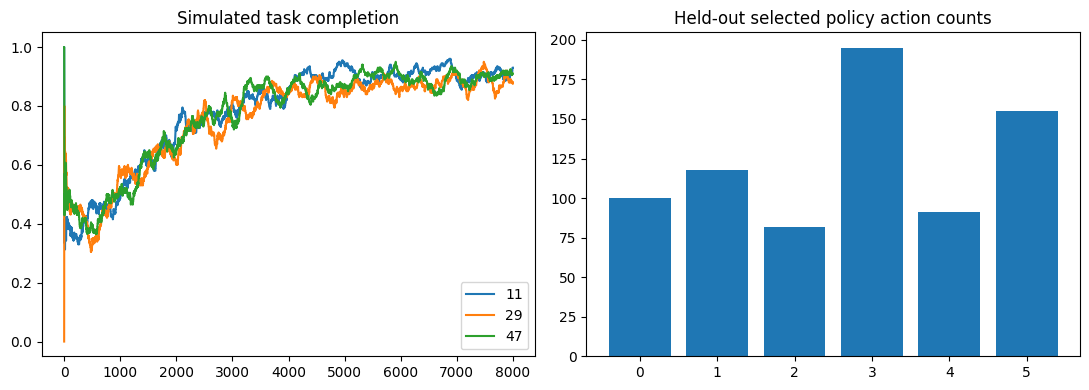

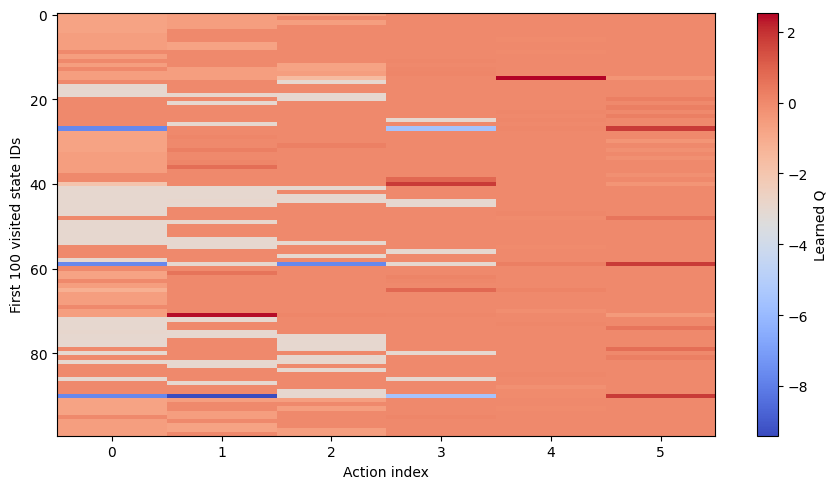

{
  "selected_seed": 11,
  "aggregate": {
    "held_out_serving": {
      "reward_mean": 4.160444444444445,
      "reward_variance_across_training_seeds": 0.007104395061728357,
      "completion_mean": 0.9444444444444444,
      "unsafe_attempts_total": 0,
      "episode_length_mean": 2.46
    },
    "held_out_unmasked": {
      "reward_mean": 4.041444444444444,
      "reward_variance_across_training_seeds": 0.009582895061728436,
      "completion_mean": 0.9400000000000001,
      "unsafe_attempts_total": 0,
      "episode_length_mean": 2.46
    },
    "baseline": {
      "reward_mean": 4.311,
      "reward_variance_across_training_seeds": 0.0,
      "completion_mean": 0.9833333333333333,
      "unsafe_attempts_total": 0,
      "episode_length_mean": 2.0366666666666666
    }
  }
}


,reward,completed,unsafe_attempts
seed,,,
11,-5.014450,0.786875,3071
29,-5.039663,0.763000,3045
47,-5.008625,0.776750,3024


Q nonzero entries: 6924
Baseline: {'average_episode_reward': 4.311, 'completion_rate': 0.9833333333333333, 'unsafe_action_attempts': 0, 'mean_episode_length': 2.0366666666666666, 'reward_variance_across_scenarios': 8.504162333333333, 'fallback_decisions': 0, 'action_counts': [35, 108, 37, 202, 75, 154]}


In [4]:
# Use the notebook-defined training function in the multi-seed harness.
import backend.app.rl.experiments as experiments
experiments.train=train
report,history,q=experiments.run_experiments()
display(history.groupby('seed').agg({'reward':'mean','completed':'mean','unsafe_attempts':'sum'}))
print('Q nonzero entries:',np.count_nonzero(q))
print('Baseline:',{k:v for k,v in report['baseline'].items() if k!='episodes'})

## Limitations
Results reflect handcrafted synthetic transition probabilities/reward. Completion is a simulator task flag, never health improvement. Report both masked deployment and unmasked diagnostic policy attempts; masking is a safety constraint shared with the baseline, not evidence that learned behavior itself is safe. Single selected policy chosen on validation only; no online learning in requests. Default runtime knowledge/engagement are declared simulated assumptions, not inferred personal traits. Simulator-to-real transfer and clinical utility are unvalidated. Baseline may outperform Q-learning; retain actual results.